<a href="https://colab.research.google.com/github/sandeepa-lak20/ML_AirSight/blob/Data_understanding/Data_understanding_of_AirSight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving PRSA2017_Data_20130301-20170228.zip to PRSA2017_Data_20130301-20170228 (1).zip


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import zipfile
import glob
import os

pd.set_option("display.max_columns", None)

In [ ]:
zip_path = "/content/PRSA2017_Data_20130301-20170228.zip"
extract_path = "/content/beijing_air_quality"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
csv_files = glob.glob(
    extract_path + "/**/*.csv",
    recursive=True
)

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(os.path.basename(file))

Number of CSV files: 12
PRSA_Data_Huairou_20130301-20170228.csv
PRSA_Data_Aotizhongxin_20130301-20170228.csv
PRSA_Data_Shunyi_20130301-20170228.csv
PRSA_Data_Nongzhanguan_20130301-20170228.csv
PRSA_Data_Wanshouxigong_20130301-20170228.csv
PRSA_Data_Gucheng_20130301-20170228.csv
PRSA_Data_Dongsi_20130301-20170228.csv
PRSA_Data_Wanliu_20130301-20170228.csv
PRSA_Data_Changping_20130301-20170228.csv
PRSA_Data_Tiantan_20130301-20170228.csv
PRSA_Data_Dingling_20130301-20170228.csv
PRSA_Data_Guanyuan_20130301-20170228.csv


In [ ]:
dataframes = []

for file in csv_files:
    station_df = pd.read_csv(file)
    dataframes.append(station_df)

df = pd.concat(dataframes, ignore_index=True)

print("Combined successfully.")
print("Dataset shape:", df.shape)

Combined successfully.
Dataset shape: (420768, 18)


In [ ]:
df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.sort_values(
    by=["station", "datetime"]
).reset_index(drop=True)

df.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Number of stations:", df["station"].nunique())
print("Starting date:", df["datetime"].min())
print("Ending date:", df["datetime"].max())

Rows: 420768
Columns: 19
Number of stations: 12
Starting date: 2013-03-01 00:00:00
Ending date: 2017-02-28 23:00:00


In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

print(
    "Duplicate station-hour records:",
    df.duplicated(
        subset=["station", "datetime"]
    ).sum()
)

Exact duplicate rows: 0
Duplicate station-hour records: 0


In [ ]:
missing_table = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing_table = missing_table[
    missing_table["Missing Values"] > 0
].sort_values(
    by="Missing Values",
    ascending=False
)

missing_table

,Missing Values,Missing Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


In [ ]:
df["PM2.5"].describe()

,PM2.5
count,412029.000000
mean,79.793428
std,80.822391
min,2.000000
25%,20.000000
50%,55.000000
75%,111.000000
max,999.000000


In [ ]:
sorted(df["station"].unique())

['Aotizhongxin',
 'Changping',
 'Dingling',
 'Dongsi',
 'Guanyuan',
 'Gucheng',
 'Huairou',
 'Nongzhanguan',
 'Shunyi',
 'Tiantan',
 'Wanliu',
 'Wanshouxigong']

In [ ]:
df.to_csv(
    "/content/beijing_air_quality_combined_raw.csv",
    index=False
)

print("Combined raw dataset saved.")

Combined raw dataset saved.


In [ ]:
clean_df = df.copy()

print("Original shape:", df.shape)
print("Working-copy shape:", clean_df.shape)

Original shape: (420768, 19)
Working-copy shape: (420768, 19)


In [ ]:
clean_df = clean_df.drop(columns=["No"])

print(clean_df.columns)

Index(['year', 'month', 'day', 'hour', 'PM2.5', 'PM10', 'SO2', 'NO2', 'CO',
       'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'wd', 'WSPM', 'station',
       'datetime'],
      dtype='object')


In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": clean_df.isna().sum(),
    "Missing_Percentage": (
        clean_df.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Count", ascending=False)

missing_summary

,Missing_Count,Missing_Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


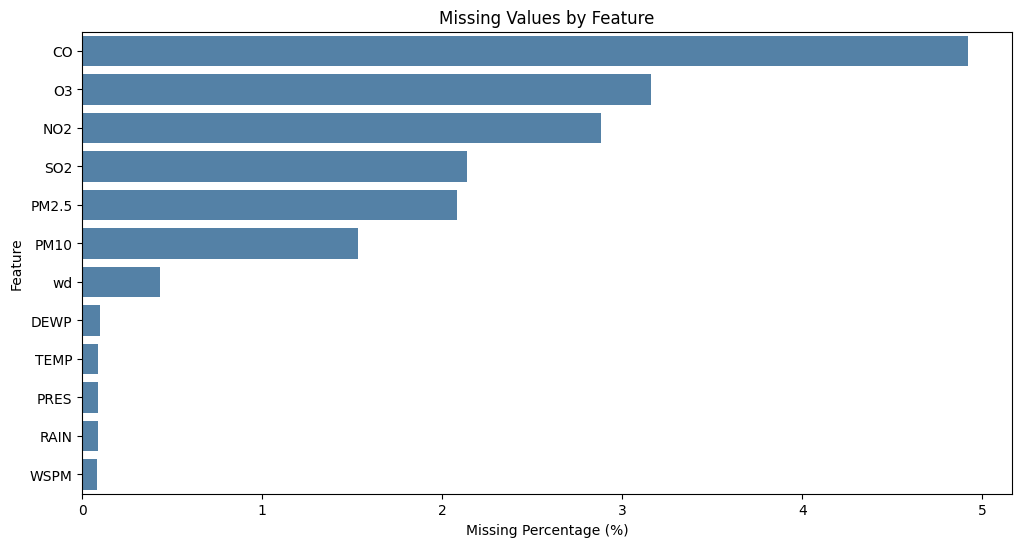

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_summary.reset_index(),
    x="Missing_Percentage",
    y="index",
    color="steelblue"
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Percentage (%)")
plt.ylabel("Feature")
plt.show()

In [ ]:
station_counts = clean_df.groupby("station").size()

print(station_counts)
print("\nAll stations complete:", (station_counts == 35064).all())

station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
dtype: int64

All stations complete: True


In [ ]:
numeric_columns = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

clean_df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
PM2.5,412029.0,79.793428,80.822391,2.0000,20.0,55.0,111.0,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.0,82.0,145.0,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.0,7.0,20.0,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.0,43.0,71.0,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.0,900.0,1500.0,10000.0
O3,407491.0,57.372271,56.661607,0.2142,11.0,45.0,82.0,1071.0
TEMP,420370.0,13.538976,11.436139,-19.9000,3.1,14.5,23.3,41.6
PRES,420375.0,1010.746982,10.474055,982.4000,1002.3,1010.4,1019.0,1042.8
DEWP,420365.0,2.490822,13.793847,-43.4000,-8.9,3.1,15.1,29.1
RAIN,420378.0,0.064476,0.821004,0.0000,0.0,0.0,0.0,72.5


In [ ]:
non_negative_columns = [
    "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "RAIN","PRES", "WSPM"
]

for column in non_negative_columns:
    negative_count = (clean_df[column] < 0).sum()
    print(column, "negative values:", negative_count)

PM2.5 negative values: 0
PM10 negative values: 0
SO2 negative values: 0
NO2 negative values: 0
CO negative values: 0
O3 negative values: 0
RAIN negative values: 0
PRES negative values: 0
WSPM negative values: 0


In [ ]:
print(
    "Temperature range:",
    clean_df["TEMP"].min(),
    "to",
    clean_df["TEMP"].max()
)

print(
    "Dew-point range:",
    clean_df["DEWP"].min(),
    "to",
    clean_df["DEWP"].max()
)

Temperature range: -19.9 to 41.6
Dew-point range: -43.4 to 29.1


In [ ]:
clean_df[
    [
        "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
        "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
    ]
].agg(["min", "max"]).T

,min,max
PM2.5,2.0000,999.0
PM10,2.0000,999.0
SO2,0.2856,500.0
NO2,1.0265,290.0
CO,100.0000,10000.0
O3,0.2142,1071.0
TEMP,-19.9000,41.6
PRES,982.4000,1042.8
DEWP,-43.4000,29.1
RAIN,0.0000,72.5


In [ ]:
print(clean_df["PM2.5"].quantile(
    [0.95, 0.99, 0.995, 0.999, 1.0]
))

print(
    "PM2.5 values equal to 999:",
    (clean_df["PM2.5"] == 999).sum()
)

0.950    242.0
0.990    370.0
0.995    432.0
0.999    564.0
1.000    999.0
Name: PM2.5, dtype: float64
PM2.5 values equal to 999: 1


In [ ]:
# Find the row containing the highest PM2.5 value
max_index = clean_df["PM2.5"].idxmax()
max_row = clean_df.loc[max_index]

event_station = max_row["station"]
event_time = max_row["datetime"]

print("Station:", event_station)
print("Event time:", event_time)
print("Maximum PM2.5:", max_row["PM2.5"])

# Display six hours before and after the event
event_window = clean_df[
    (clean_df["station"] == event_station) &
    (
        clean_df["datetime"].between(
            event_time - pd.Timedelta(hours=6),
            event_time + pd.Timedelta(hours=6)
        )
    )
]

display(
    event_window[
        [
            "station", "datetime", "PM2.5", "PM10",
            "SO2", "NO2", "CO", "O3", "WSPM"
        ]
    ]
)

Station: Wanshouxigong
Event time: 2016-02-08 02:00:00
Maximum PM2.5: 999.0


,station,datetime,PM2.5,PM10,SO2,NO2,CO,O3,WSPM
411476,Wanshouxigong,2016-02-07 20:00:00,104.0,140.0,34.0,40.0,1200.0,54.0,1.4
411477,Wanshouxigong,2016-02-07 21:00:00,54.0,106.0,19.0,23.0,900.0,65.0,1.5
411478,Wanshouxigong,2016-02-07 22:00:00,74.0,129.0,22.0,29.0,1000.0,53.0,0.7
411479,Wanshouxigong,2016-02-07 23:00:00,171.0,230.0,61.0,60.0,1800.0,16.0,0.9
411480,Wanshouxigong,2016-02-08 00:00:00,238.0,340.0,117.0,74.0,1900.0,3.0,0.2
411481,Wanshouxigong,2016-02-08 01:00:00,826.0,NaN,411.0,81.0,2400.0,7.0,1.5
411482,Wanshouxigong,2016-02-08 02:00:00,999.0,NaN,299.0,82.0,2700.0,6.0,1.1
411483,Wanshouxigong,2016-02-08 03:00:00,857.0,NaN,256.0,82.0,2400.0,6.0,0.6
411484,Wanshouxigong,2016-02-08 04:00:00,748.0,929.0,236.0,83.0,2900.0,9.0,1.1
411485,Wanshouxigong,2016-02-08 05:00:00,662.0,829.0,186.0,76.0,2600.0,8.0,0.7


In [ ]:
# Ensure observations are in the correct chronological order
clean_df = clean_df.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

# Get the next observation from the same station
clean_df["next_datetime"] = (
    clean_df.groupby("station")["datetime"].shift(-1)
)

clean_df["next_hour_pm25"] = (
    clean_df.groupby("station")["PM2.5"].shift(-1)
)

# Calculate the time difference
clean_df["time_gap_hours"] = (
    clean_df["next_datetime"] - clean_df["datetime"]
).dt.total_seconds() / 3600

In [ ]:
%whos


Variable               Type         Data/Info
---------------------------------------------
axes                   ndarray      12: 12 elems, type `object`, 96 bytes
classify_air_quality   function     <function classify_air_quality at 0x7f1d8e7b8860>
clean_df               DataFrame            year  month  day <...>420768 rows x 21 columns]
column                 str          WSPM
corr_matrix            DataFrame              PM2.5      PM10<...>591  0.021022  1.000000  
correlation_columns    list         n=11
coverage               DataFrame                   total_rows<...>0                     0  
coverage_df            DataFrame            year  month  day <...>420768 rows x 23 columns]
csv_files              list         n=12
dataframes             list         n=12
df                     DataFrame               No  year  mont<...>420768 rows x 19 columns]
event_station          str          Wanshouxigong
event_time             Timestamp    2016-02-08 02:00:00
event_window      

In [ ]:
clean_df["valid_target"] = (
    (clean_df["time_gap_hours"] == 1) &
    (clean_df["next_hour_pm25"].notna())
)

print(clean_df["valid_target"].value_counts())

valid_target
True     412017
False      8751
Name: count, dtype: int64


In [ ]:
import numpy as np

def classify_air_quality(pm25):
    if pd.isna(pm25):
        return np.nan
    elif pm25 <= 35:
        return "Good"
    elif pm25 <= 75:
        return "Moderate"
    elif pm25 <= 115:
        return "Unhealthy"
    elif pm25 <= 150:
        return "Very Unhealthy"
    else:
        return "Hazardous"


clean_df["target"] = np.where(
    clean_df["valid_target"],
    clean_df["next_hour_pm25"].apply(classify_air_quality),
    np.nan
)

In [ ]:
model_df = clean_df[
    clean_df["valid_target"]
].copy().reset_index(drop=True)

print("Original rows:", len(clean_df))
print("Usable modelling rows:", len(model_df))
print("Removed rows:", len(clean_df) - len(model_df))

print("\nTarget class distribution:")
print(model_df["target"].value_counts())

Original rows: 420768
Usable modelling rows: 412017
Removed rows: 8751

Target class distribution:
target
Good              153859
Moderate           97156
Unhealthy          63782
Hazardous          62670
Very Unhealthy     34550
Name: count, dtype: int64


In [ ]:
print(
    "Targets with an incorrect time gap:",
    (model_df["time_gap_hours"] != 1).sum()
)

display(
    model_df[
        [
            "station",
            "datetime",
            "PM2.5",
            "next_datetime",
            "next_hour_pm25",
            "time_gap_hours",
            "target"
        ]
    ].head(20)
)

Targets with an incorrect time gap: 0


,station,datetime,PM2.5,next_datetime,next_hour_pm25,time_gap_hours,target
0,Aotizhongxin,2013-03-01 00:00:00,4.0,2013-03-01 01:00:00,8.0,1.0,Good
1,Aotizhongxin,2013-03-01 01:00:00,8.0,2013-03-01 02:00:00,7.0,1.0,Good
2,Aotizhongxin,2013-03-01 02:00:00,7.0,2013-03-01 03:00:00,6.0,1.0,Good
3,Aotizhongxin,2013-03-01 03:00:00,6.0,2013-03-01 04:00:00,3.0,1.0,Good
4,Aotizhongxin,2013-03-01 04:00:00,3.0,2013-03-01 05:00:00,5.0,1.0,Good
5,Aotizhongxin,2013-03-01 05:00:00,5.0,2013-03-01 06:00:00,3.0,1.0,Good
6,Aotizhongxin,2013-03-01 06:00:00,3.0,2013-03-01 07:00:00,3.0,1.0,Good
7,Aotizhongxin,2013-03-01 07:00:00,3.0,2013-03-01 08:00:00,3.0,1.0,Good
8,Aotizhongxin,2013-03-01 08:00:00,3.0,2013-03-01 09:00:00,3.0,1.0,Good
9,Aotizhongxin,2013-03-01 09:00:00,3.0,2013-03-01 10:00:00,3.0,1.0,Good


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

print("Dataset shape:", clean_df.shape)
print("Stations:", clean_df["station"].nunique())
print("Date range:", clean_df["datetime"].min(),
      "to", clean_df["datetime"].max())

display(clean_df[numeric_columns].describe().T)

Dataset shape: (420768, 23)
Stations: 12
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,count,mean,std,min,25%,50%,75%,max
PM2.5,412029.0,79.793428,80.822391,2.0000,20.0,55.0,111.0,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.0,82.0,145.0,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.0,7.0,20.0,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.0,43.0,71.0,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.0,900.0,1500.0,10000.0
O3,407491.0,57.372271,56.661607,0.2142,11.0,45.0,82.0,1071.0
TEMP,420370.0,13.538976,11.436139,-19.9000,3.1,14.5,23.3,41.6
PRES,420375.0,1010.746982,10.474055,982.4000,1002.3,1010.4,1019.0,1042.8
DEWP,420365.0,2.490822,13.793847,-43.4000,-8.9,3.1,15.1,29.1
RAIN,420378.0,0.064476,0.821004,0.0000,0.0,0.0,0.0,72.5


,Feature,Skewness
9,RAIN,30.044
2,SO2,3.010
4,CO,2.570
0,PM2.5,2.014
1,PM10,1.886
5,O3,1.660
10,WSPM,1.626
3,NO2,1.050
7,PRES,0.106
6,TEMP,-0.104


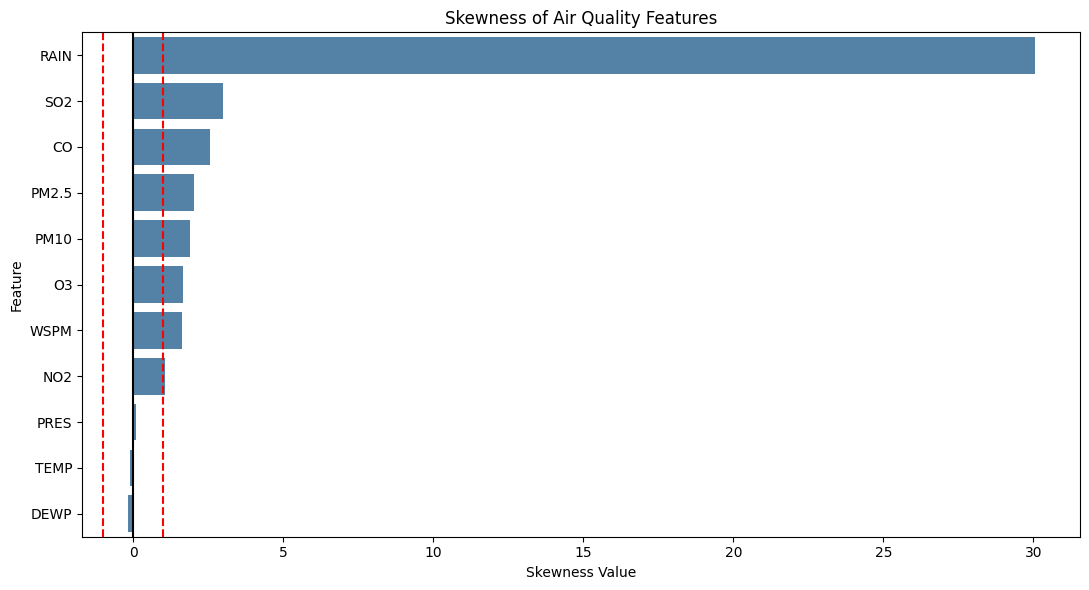

In [ ]:
skewness = clean_df[numeric_columns].skew()

skew_table = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
}).sort_values("Skewness", ascending=False)

display(skew_table.round(3))

plt.figure(figsize=(11, 6))

sns.barplot(
    data=skew_table,
    x="Skewness",
    y="Feature",
    color="steelblue"
)

plt.axvline(0, color="black")
plt.axvline(1, color="red", linestyle="--")
plt.axvline(-1, color="red", linestyle="--")

plt.title("Skewness of Air Quality Features")
plt.xlabel("Skewness Value")
plt.tight_layout()
plt.show()

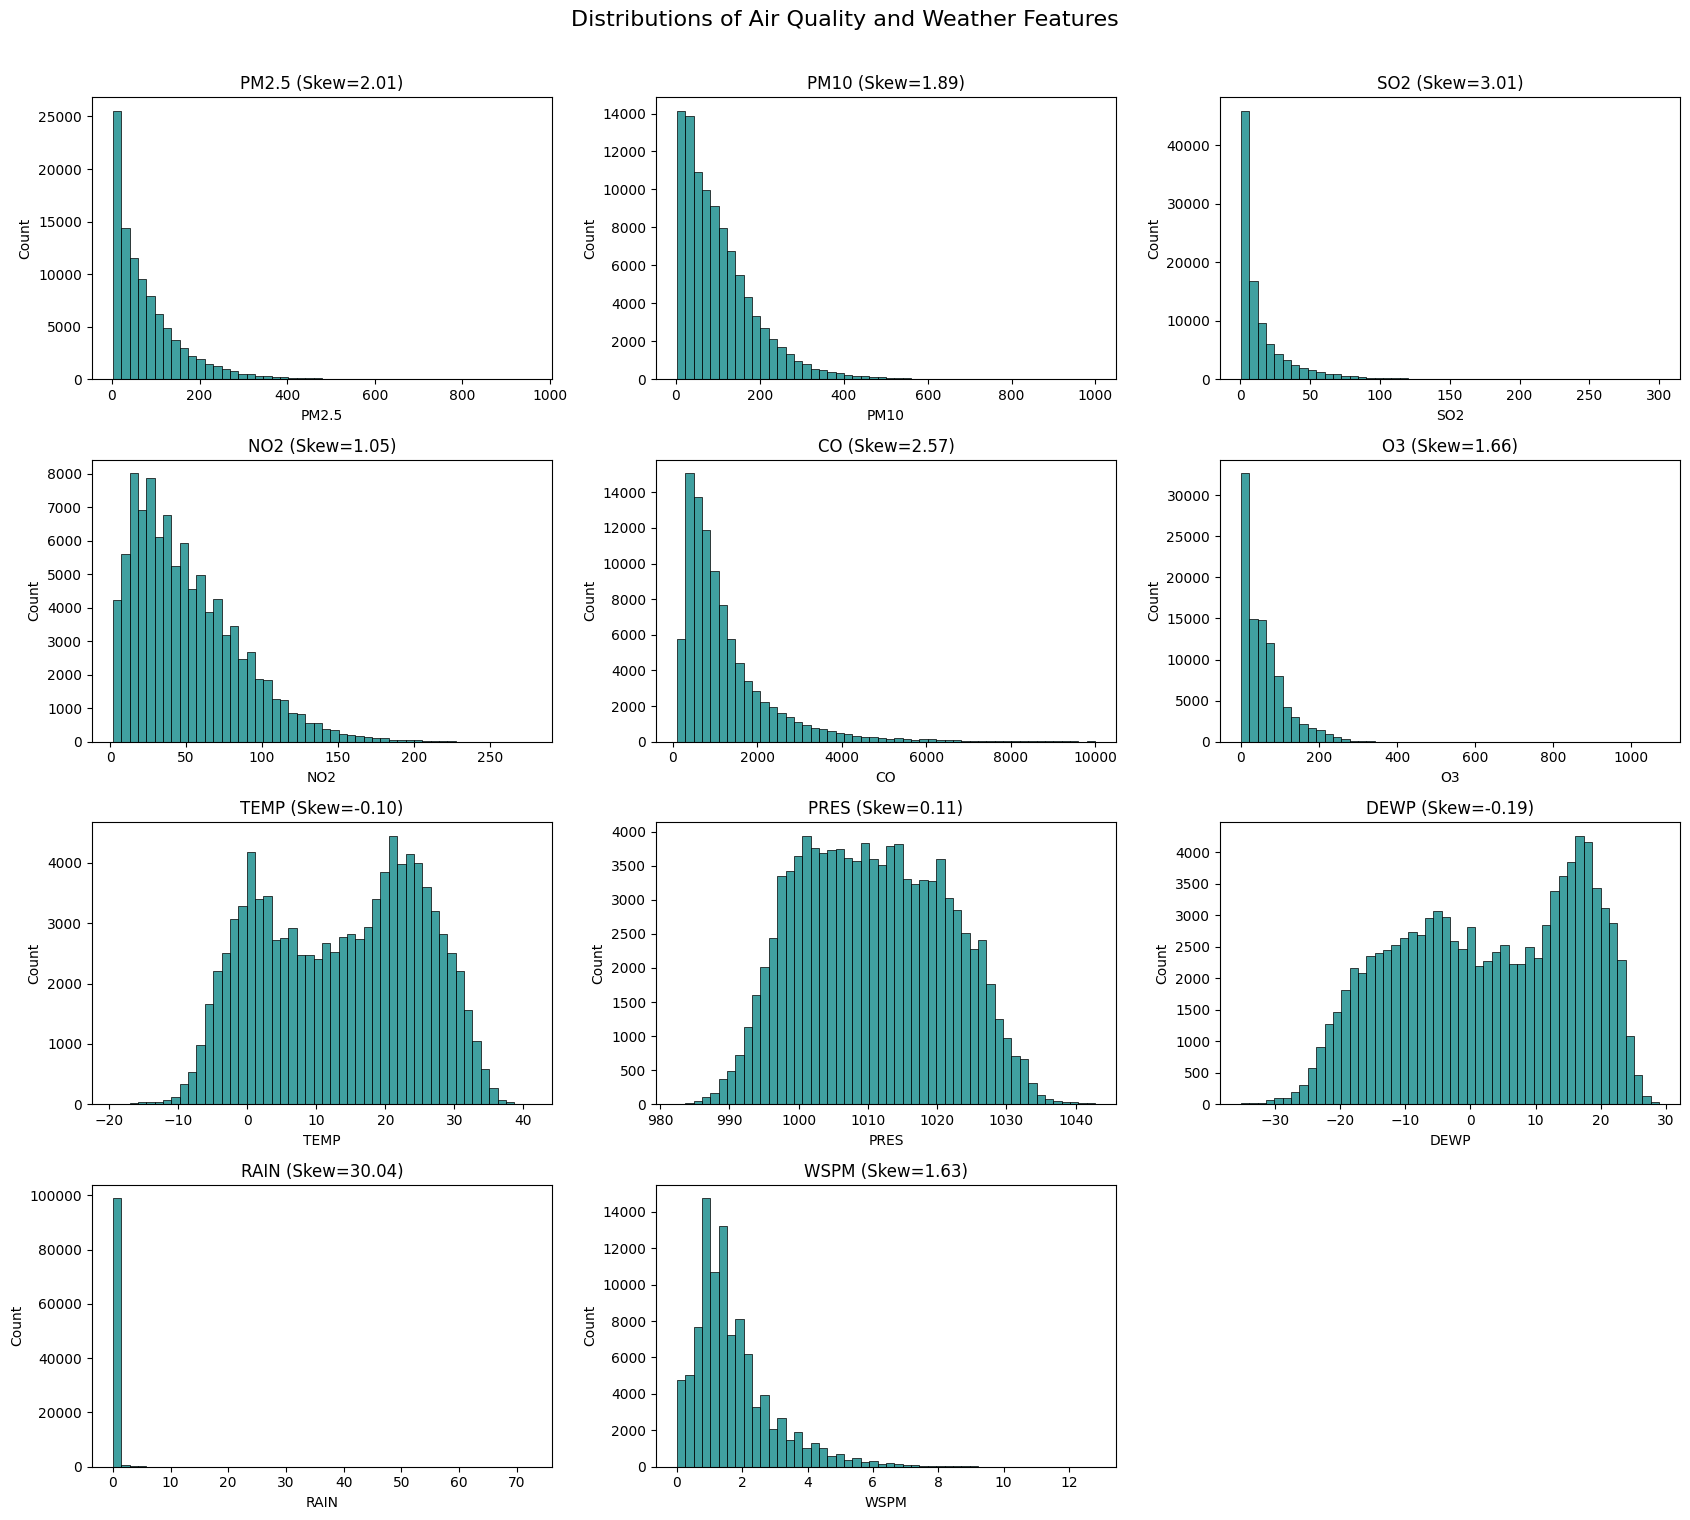

In [ ]:
plot_df = clean_df[numeric_columns].sample(
    n=min(100000, len(clean_df)),
    random_state=42
)

fig, axes = plt.subplots(4, 3, figsize=(17, 15))
axes = axes.flatten()

for i, column in enumerate(numeric_columns):
    sns.histplot(
        plot_df[column].dropna(),
        bins=50,
        ax=axes[i],
        color="teal"
    )

    axes[i].set_title(
        f"{column} (Skew={skewness[column]:.2f})"
    )

for i in range(len(numeric_columns), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle(
    "Distributions of Air Quality and Weather Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

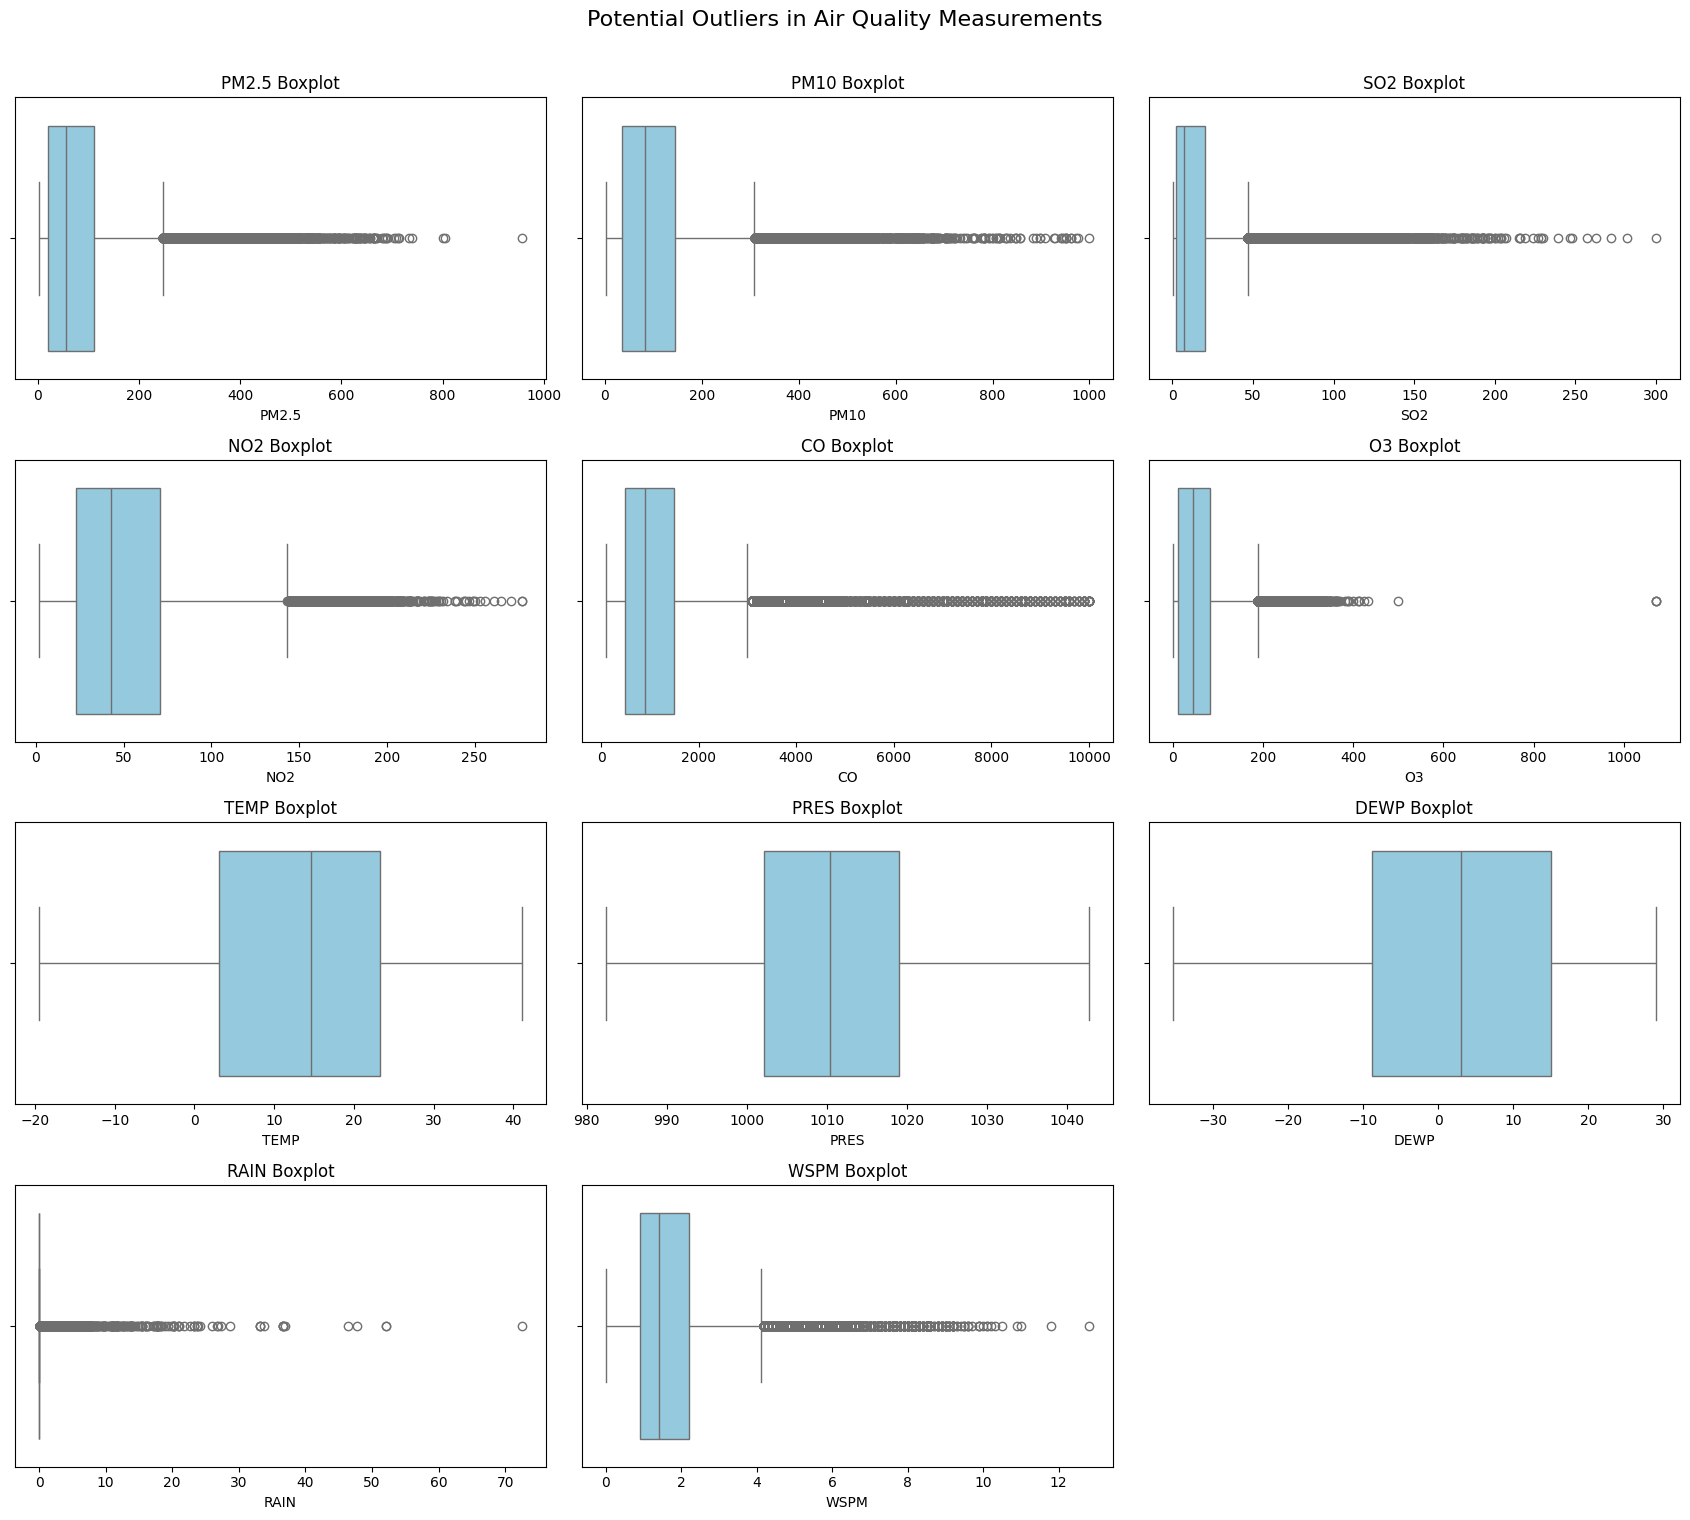

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(17, 15))
axes = axes.flatten()

for i, column in enumerate(numeric_columns):
    sns.boxplot(
        x=plot_df[column],
        ax=axes[i],
        color="skyblue"
    )

    axes[i].set_title(f"{column} Boxplot")

for i in range(len(numeric_columns), len(axes)):
    fig.delaxes(axes[i])

plt.suptitle(
    "Potential Outliers in Air Quality Measurements",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
station,,,,,,,,,,,
Aotizhongxin,2.64,2.05,2.67,2.92,5.07,4.90,0.06,0.06,0.06,0.06,0.04
Changping,2.21,1.66,1.79,1.90,4.34,1.72,0.15,0.14,0.15,0.15,0.12
Dingling,2.22,1.87,2.08,3.52,5.74,3.46,0.15,0.14,0.15,0.15,0.12
Dongsi,2.14,1.58,1.89,4.57,9.12,1.89,0.06,0.06,0.06,0.06,0.04
Guanyuan,1.76,1.22,1.35,1.88,5.00,3.35,0.06,0.06,0.06,0.06,0.04
Gucheng,1.84,1.09,1.45,1.91,4.00,2.08,0.15,0.14,0.15,0.12,0.12
Huairou,2.72,2.22,2.79,4.67,4.06,3.28,0.15,0.15,0.15,0.16,0.14
Nongzhanguan,1.79,1.25,1.27,1.97,3.44,1.44,0.06,0.06,0.06,0.06,0.04
Shunyi,2.60,1.56,3.70,3.89,6.21,4.25,0.15,0.15,0.15,0.15,0.13


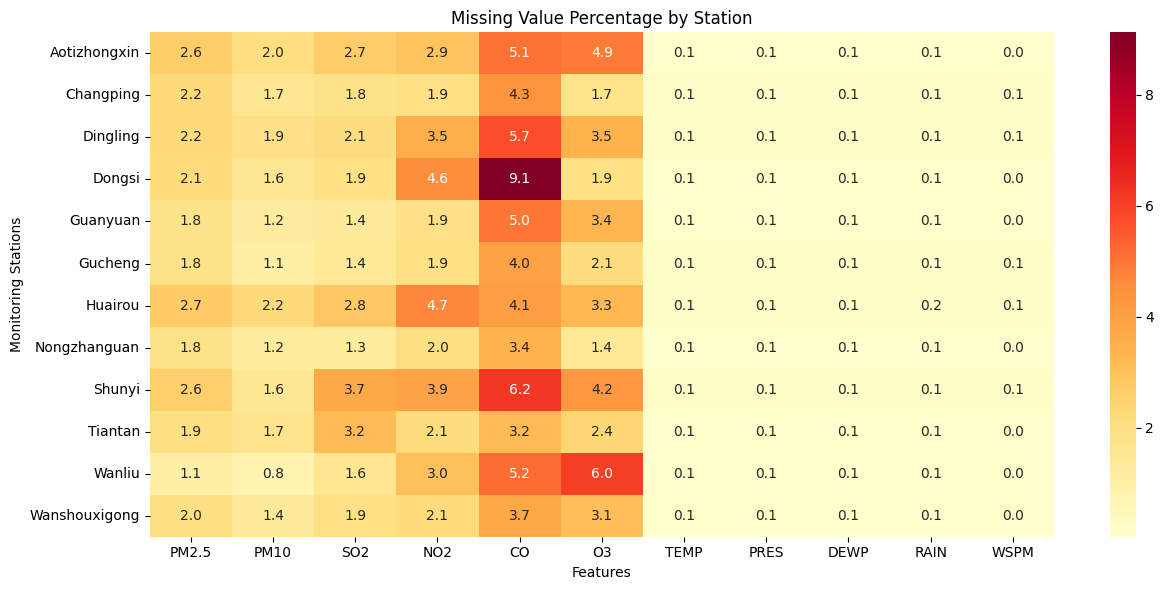

In [ ]:

# Missing values by monitoring station
station_missing = clean_df.groupby("station")[
    numeric_columns
].apply(lambda x: x.isna().mean() * 100)

station_missing = station_missing.round(2)

display(station_missing)

# Heatmap
plt.figure(figsize=(13, 6))

sns.heatmap(
    station_missing,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Missing Value Percentage by Station")
plt.xlabel("Features")
plt.ylabel("Monitoring Stations")
plt.tight_layout()
plt.show()


,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
station,,,,,,,,,,,
Aotizhongxin,925,718,935,1023,1776,1719,20,20,20,20,14
Changping,774,582,628,667,1521,604,53,50,53,51,43
Dingling,779,656,730,1234,2012,1214,53,50,53,51,43
Dongsi,750,553,663,1601,3197,664,20,20,20,20,14
Guanyuan,616,429,474,659,1753,1173,20,20,20,20,14
Gucheng,646,381,507,668,1401,729,51,50,51,43,42
Huairou,953,777,980,1639,1422,1151,51,53,53,55,49
Nongzhanguan,628,440,446,692,1206,506,20,20,20,20,14
Shunyi,913,548,1296,1365,2178,1489,51,51,54,51,44


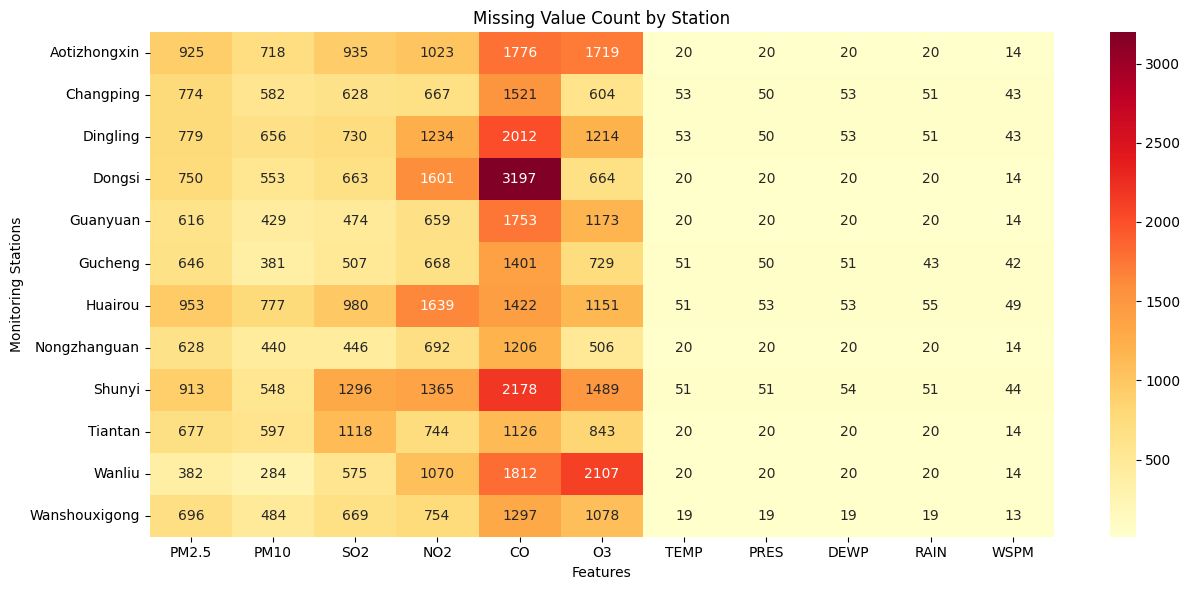

In [ ]:

# Missing value counts for each station
station_missing = clean_df.groupby("station")[
    numeric_columns
].apply(lambda x: x.isna().sum())

display(station_missing)

# Heatmap
plt.figure(figsize=(13, 6))

sns.heatmap(
    station_missing,
    annot=True,
    fmt="d",
    cmap="YlOrRd"
)

plt.title("Missing Value Count by Station")
plt.xlabel("Features")
plt.ylabel("Monitoring Stations")
plt.tight_layout()
plt.show()


In [ ]:

# Station-wise data quality summary

station_summary = clean_df.groupby("station").agg(
    total_rows=("PM2.5", "size"),
    missing_pm25=("PM2.5", lambda x: x.isna().sum())
)

station_summary["total_missing"] = (
    clean_df.groupby("station")[numeric_columns]
    .apply(lambda x: x.isna().sum().sum())
)

station_summary["complete_rows"] = (
    clean_df.groupby("station")[numeric_columns]
    .apply(lambda x: x.notna().all(axis=1).sum())
)

station_summary = station_summary.sort_values(
    by="total_missing"
)

display(station_summary)


,total_rows,missing_pm25,total_missing,complete_rows
station,,,,
Nongzhanguan,35064,628,4012,33176
Gucheng,35064,646,4569,32615
Changping,35064,774,5026,32774
Wanshouxigong,35064,696,5067,32829
Guanyuan,35064,616,5198,32328
Tiantan,35064,677,5199,32907
Wanliu,35064,382,6324,30737
Dingling,35064,779,6875,31399
Huairou,35064,953,7183,31955


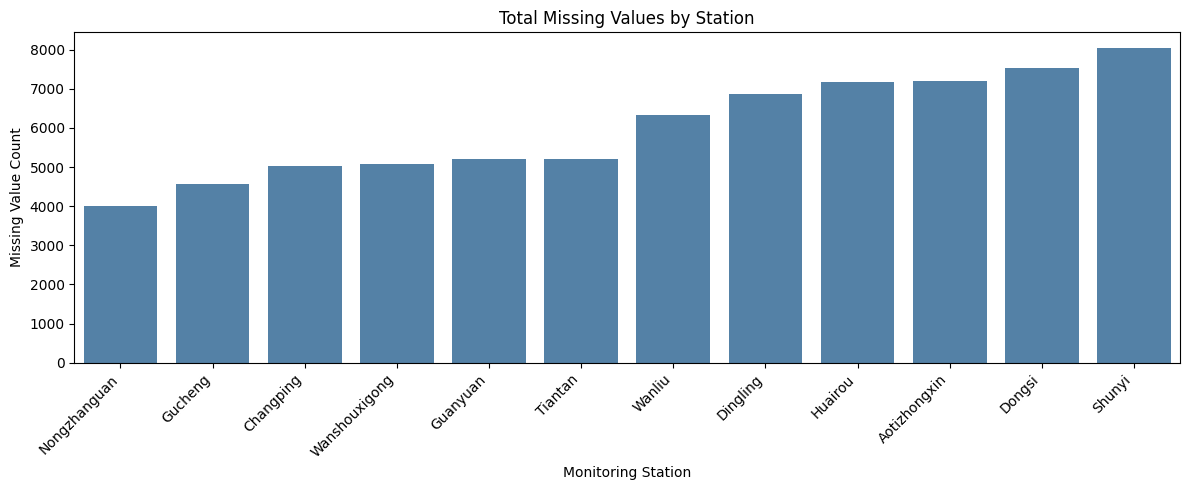

In [ ]:

plt.figure(figsize=(12, 5))

sns.barplot(
    data=station_summary.reset_index(),
    x="station",
    y="total_missing",
    color="steelblue"
)

plt.xticks(rotation=45, ha="right")
plt.title("Total Missing Values by Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Missing Value Count")
plt.tight_layout()
plt.show()


In [ ]:

# Station-wise Time Coverage Analysis

coverage_df = clean_df.copy()

coverage_df["datetime"] = pd.to_datetime(
    coverage_df[["year", "month", "day", "hour"]]
)

coverage = coverage_df.groupby("station").agg(
    total_rows=("datetime", "size"),
    start_date=("datetime", "min"),
    end_date=("datetime", "max"),
    unique_timestamps=("datetime", "nunique")
)

coverage["expected_hours"] = (
    (coverage["end_date"] - coverage["start_date"])
    / pd.Timedelta(hours=1)
).astype(int) + 1

coverage["missing_timestamps"] = (
    coverage["expected_hours"]
    - coverage["unique_timestamps"]
)

coverage["duplicate_timestamps"] = (
    coverage["total_rows"]
    - coverage["unique_timestamps"]
)

display(coverage)


,total_rows,start_date,end_date,unique_timestamps,expected_hours,missing_timestamps,duplicate_timestamps
station,,,,,,,
Aotizhongxin,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Changping,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Dingling,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Dongsi,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Guanyuan,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Gucheng,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Huairou,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Nongzhanguan,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0
Shunyi,35064,2013-03-01,2017-02-28 23:00:00,35064,35064,0,0


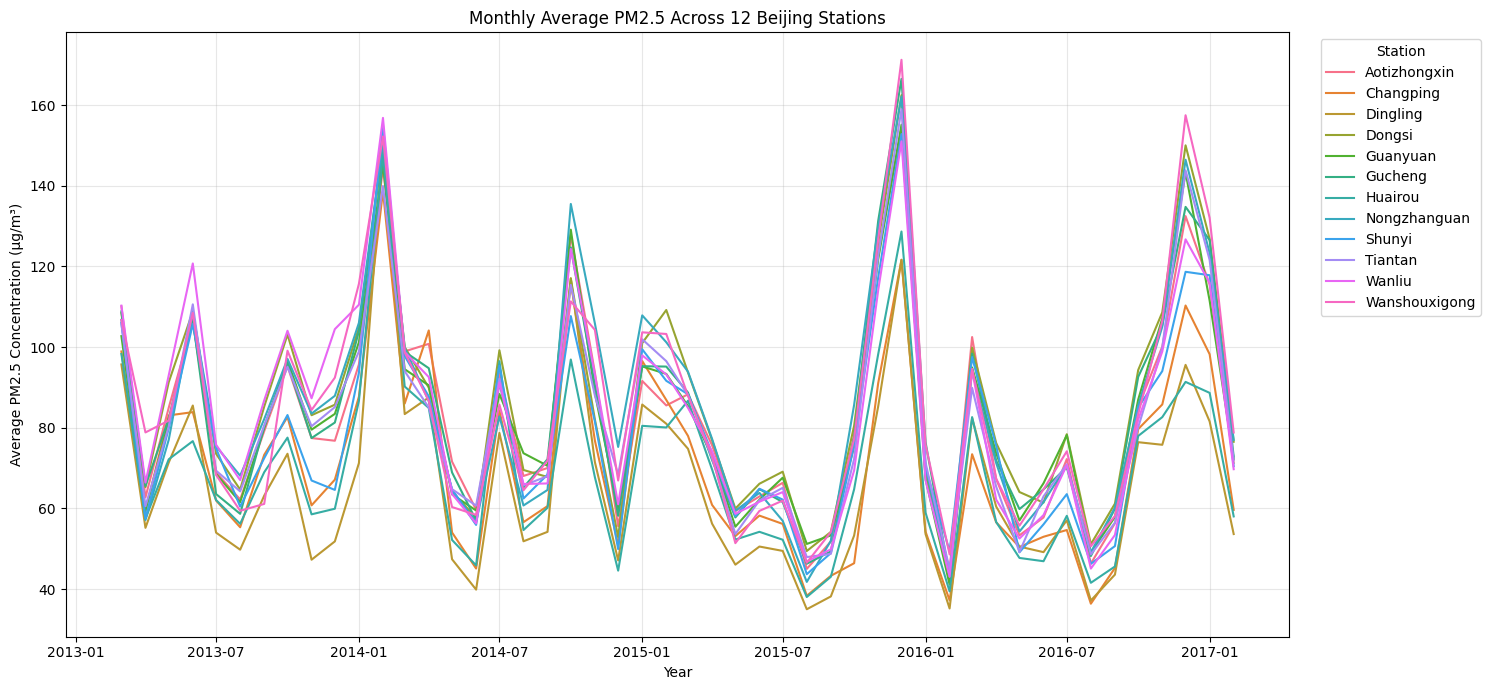

In [ ]:

# PM2.5 Time-Series Visualization
# Monthly average for all 12 stations

time_df = clean_df.copy()

time_df["datetime"] = pd.to_datetime(
    time_df[["year", "month", "day", "hour"]]
)

time_df["year_month"] = (
    time_df["datetime"].dt.to_period("M").dt.to_timestamp()
)

monthly_pm25 = (
    time_df.groupby(["year_month", "station"])["PM2.5"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(15, 7))

sns.lineplot(
    data=monthly_pm25,
    x="year_month",
    y="PM2.5",
    hue="station"
)

plt.title("Monthly Average PM2.5 Across 12 Beijing Stations")
plt.xlabel("Year")
plt.ylabel("Average PM2.5 Concentration (µg/m³)")
plt.legend(
    title="Station",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


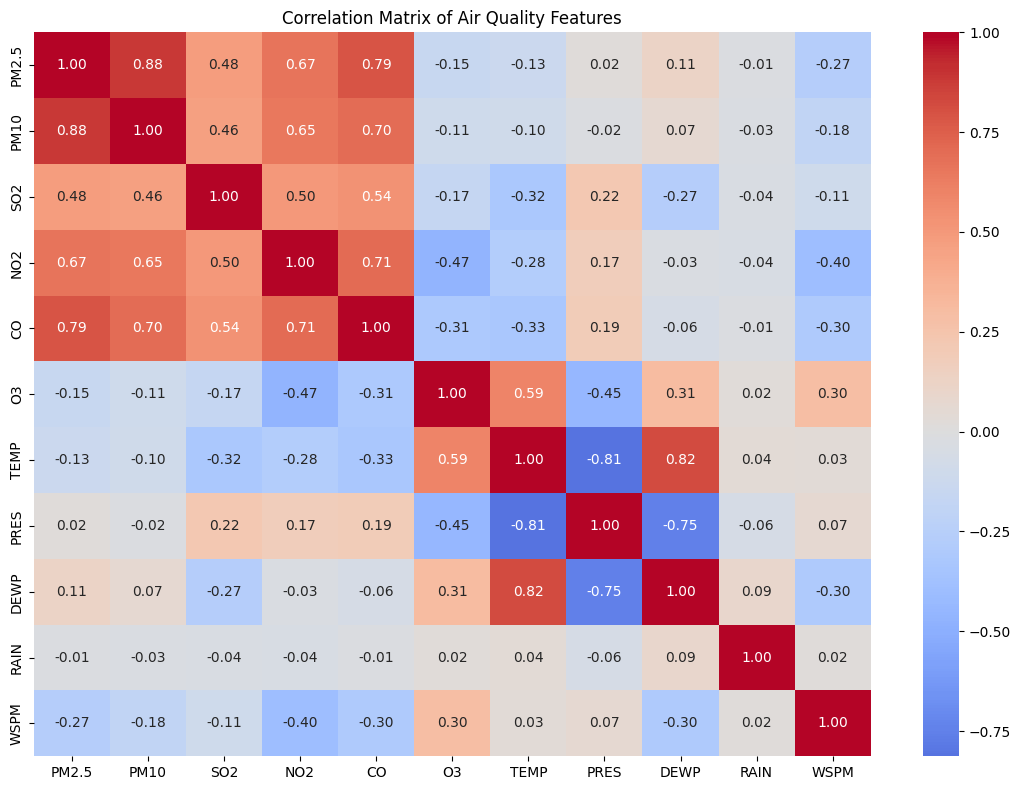

In [ ]:

# Correlation Analysis

correlation_columns = [
    "PM2.5", "PM10", "SO2", "NO2",
    "CO", "O3", "TEMP", "PRES",
    "DEWP", "RAIN", "WSPM"
]

corr_matrix = clean_df[
    correlation_columns
].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Air Quality Features")
plt.tight_layout()
plt.show()


In [ ]:

# Wind Direction Analysis

print("Unique wind directions:")
print(clean_df["wd"].dropna().unique())

print("\nNumber of categories:")
print(clean_df["wd"].nunique())

print("\nMissing wind direction values:")
print(clean_df["wd"].isna().sum())

print("\nWind direction counts:")
display(
    clean_df["wd"].value_counts(dropna=False)
)


Unique wind directions:
['NNW' 'N' 'NW' 'NNE' 'ENE' 'E' 'NE' 'W' 'SSW' 'WSW' 'SE' 'WNW' 'SSE'
 'ESE' 'S' 'SW']

Number of categories:
16

Missing wind direction values:
1822

Wind direction counts:


,count
wd,
NE,43335
ENE,34142
NW,32600
N,30869
E,29752
SW,28756
NNE,28232
NNW,25326
WNW,24375


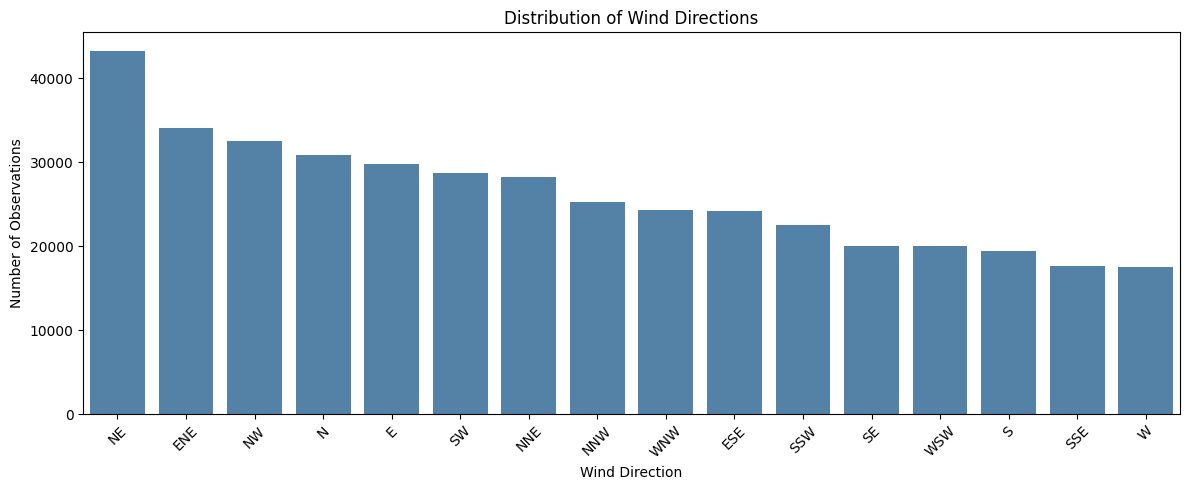

In [ ]:

plt.figure(figsize=(12, 5))

sns.countplot(
    data=clean_df,
    x="wd",
    order=clean_df["wd"].value_counts().index,
    color="steelblue"
)

plt.title("Distribution of Wind Directions")
plt.xlabel("Wind Direction")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,PM2.5
wd,
ESE,102.006032
E,101.710109
ENE,97.826575
SE,96.568718
SSE,93.524343
S,89.344021
NE,86.074420
SSW,83.951593
SW,79.324547


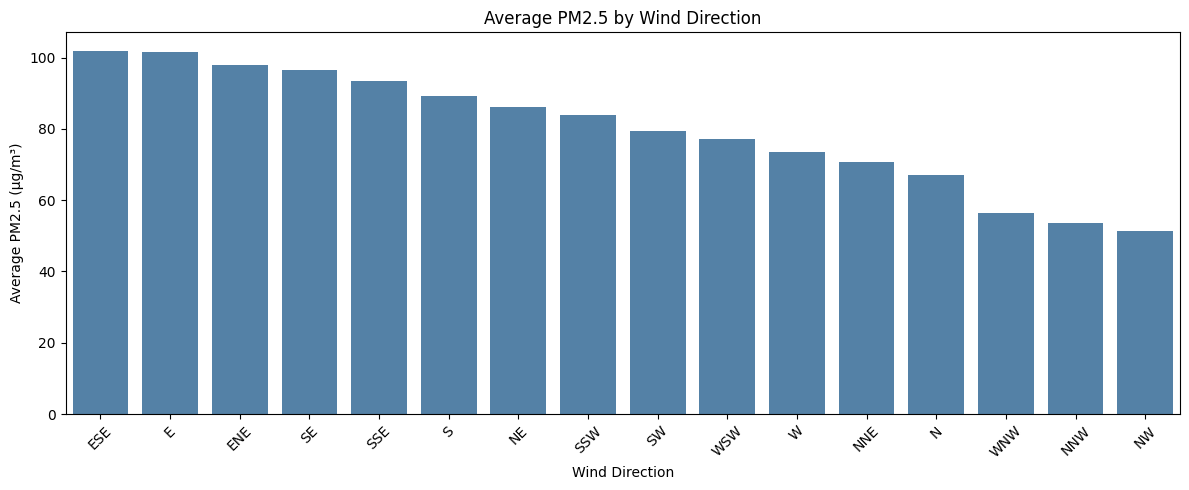

In [ ]:

wind_pm25 = (
    clean_df.groupby("wd")["PM2.5"]
    .mean()
    .sort_values(ascending=False)
)

display(wind_pm25)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=wind_pm25.index,
    y=wind_pm25.values,
    color="steelblue"
)

plt.title("Average PM2.5 by Wind Direction")
plt.xlabel("Wind Direction")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

# Target Class Distribution Analysis

class_order = [
    "Good",
    "Moderate",
    "Unhealthy",
    "Very Unhealthy",
    "Hazardous"
]

target_counts = (
    model_df["target"]
    .value_counts()
    .reindex(class_order, fill_value=0)
)

target_percentages = (
    target_counts / target_counts.sum() * 100
).round(2)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages
})

display(target_summary)

print("Total valid target records:", target_counts.sum())


,Count,Percentage (%)
target,,
Good,153859,37.34
Moderate,97156,23.58
Unhealthy,63782,15.48
Very Unhealthy,34550,8.39
Hazardous,62670,15.21


Total valid target records: 412017


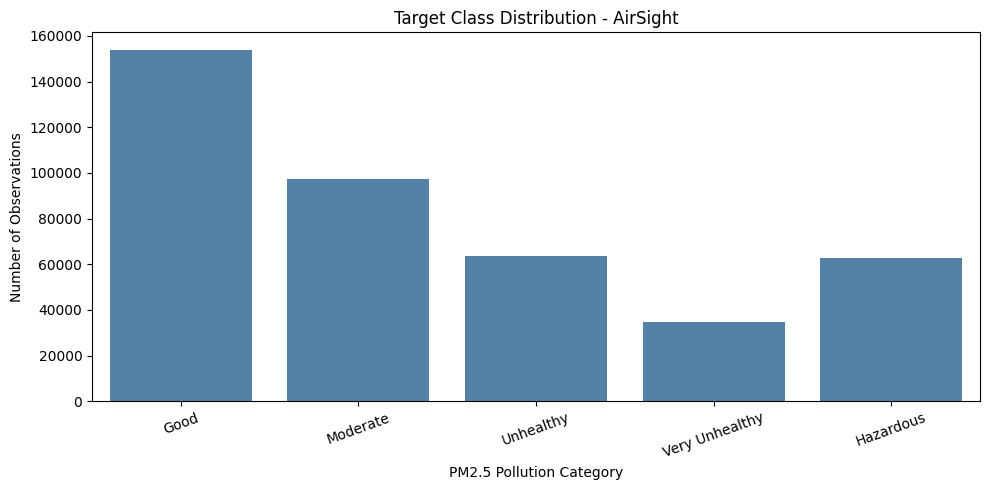

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    x=target_counts.index,
    y=target_counts.values,
    color="steelblue"
)

plt.title("Target Class Distribution - AirSight")
plt.xlabel("PM2.5 Pollution Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


target,Good,Moderate,Unhealthy,Very Unhealthy,Hazardous
station,,,,,
Aotizhongxin,12140,8103,5481,2888,5526
Changping,14529,7897,4864,2625,4374
Dingling,15964,7572,4326,2438,3984
Dongsi,11919,7851,5577,3026,5940
Guanyuan,11926,8285,5731,3074,5431
Gucheng,11665,8495,5652,3145,5460
Huairou,14503,8069,4772,2676,4090
Nongzhanguan,12204,8067,5520,2842,5802
Shunyi,12924,7907,5174,2918,5227


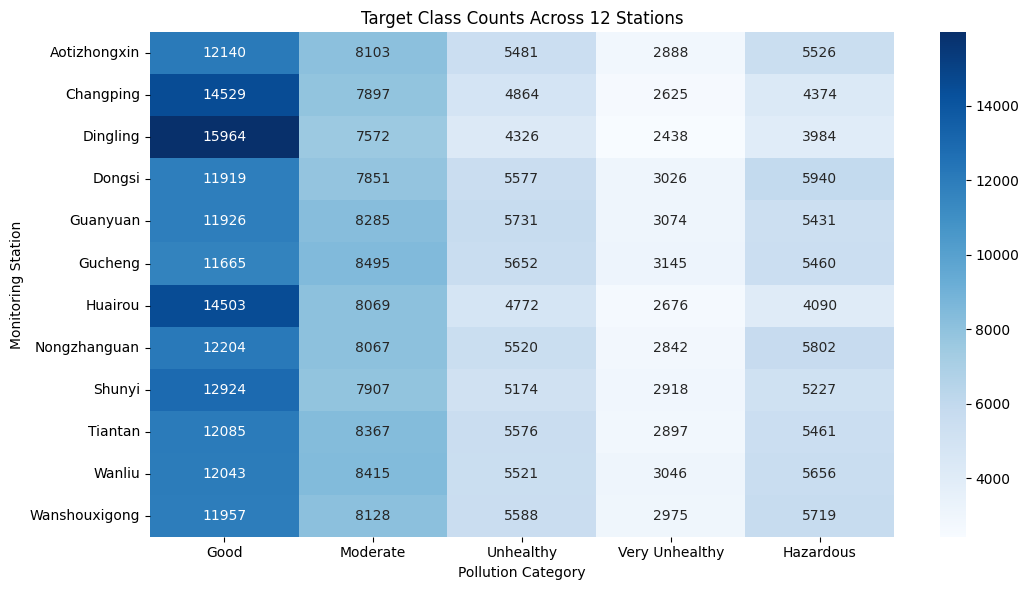

In [ ]:

station_target = pd.crosstab(
    model_df["station"],
    model_df["target"]
)

station_target = station_target.reindex(
    columns=class_order,
    fill_value=0
)

display(station_target)

plt.figure(figsize=(11, 6))

sns.heatmap(
    station_target,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Target Class Counts Across 12 Stations")
plt.xlabel("Pollution Category")
plt.ylabel("Monitoring Station")

plt.tight_layout()
plt.show()
